In [10]:
import ast
import re
import matplotlib.pyplot as plt

In [11]:
import os; print("✅ Both files uploaded successfully!" if os.path.exists("Environment.txt") and os.path.exists("Schedule.txt") else "❌ Missing file(s)! Check exact filenames.")

✅ Both files uploaded successfully!


In [12]:
def parse_coordinates(text):
    coordinates = ast.literal_eval(text.strip())
    if isinstance(coordinates, tuple) and len(coordinates) == 2 and all(isinstance(x, int) for x in coordinates):
        coordinates = [coordinates]
    return [tuple(point) for point in coordinates]

def load_environment(filename):
    with open(filename, "r") as file:
        lines = [line.strip() for line in file if line.strip()]

    rows, cols = map(int, lines[0].split(","))
    obstacles = set(parse_coordinates(lines[2]))
    dirty_locations = parse_coordinates(lines[4])
    charging_station = parse_coordinates(lines[5])[0]

    return {
        "rows": rows,
        "cols": cols,
        "obstacles": obstacles,
        "dirty_locations": dirty_locations,
        "charging_station": charging_station
    }

def load_csp(grid, sched_filename):
    # Create CSP variables D1, D2, ... from dirty locations in Environment.txt
    variables = [f"D{i + 1}" for i in range(len(grid["dirty_locations"]))]
    dirty_map = {f"D{i + 1}": coord for i, coord in enumerate(grid["dirty_locations"])}

    with open(sched_filename, "r") as f:
        sched_text = f.read()

    # Extract counts: [num_slots, num_precedence, num_latest]
    counts = [int(x) for x in re.sub(r"\([^)]*\)", "", sched_text).split()]
    num_slots, num_prec = counts[0], counts[1]

    # Extract (X, Y) constraint pairs
    pairs = re.findall(r"\(\s*([A-Za-z0-9]+)\s*,\s*([A-Za-z0-9]+)\s*\)", sched_text)

    time_slots = [f"T{i + 1}" for i in range(num_slots)]
    domains = {var: list(time_slots) for var in variables}

    constraints = {
        "time_slots": time_slots,
        "precedence": pairs[:num_prec],
        "latest_slot": pairs[num_prec:]
    }

    return variables, dirty_map, domains, constraints

grid = load_environment("Environment.txt")
variables, dirty_map, domains, constraints = load_csp(grid, "Schedule.txt")

print("CSP Variables & Locations:", dirty_map)
print("Available Time Slots:", constraints["time_slots"])
print("Precedence Constraints:", constraints["precedence"])
print("Latest-Slot Constraints:", constraints["latest_slot"])

CSP Variables & Locations: {'D1': (5, 3), 'D2': (4, 4), 'D3': (1, 2), 'D4': (6, 7)}
Available Time Slots: ['T1', 'T2', 'T3', 'T4']
Precedence Constraints: [('D3', 'D1'), ('D1', 'D2'), ('D3', 'D4')]
Latest-Slot Constraints: [('D1', 'T2'), ('D4', 'T3')]


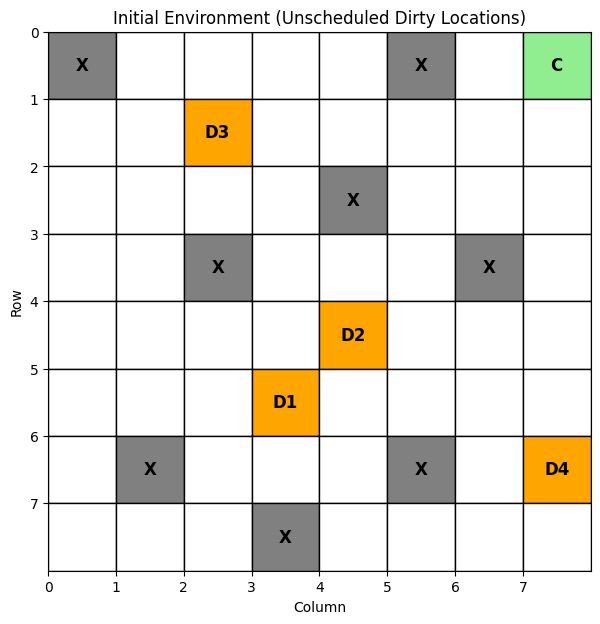

In [13]:
def display_grid(grid):
    rows, cols = grid["rows"], grid["cols"]
    fig, ax = plt.subplots(figsize=(7, 7))
    ax.set_xlim(0, cols)
    ax.set_ylim(rows, 0)

    for r in range(rows):
        for c in range(cols):
            color, label = "white", ""
            if (r, c) in grid["obstacles"]:
                color, label = "gray", "X"
            elif (r, c) in grid["dirty_locations"]:
                color = "orange"
                label = f"D{grid['dirty_locations'].index((r, c)) + 1}"
            elif (r, c) == grid["charging_station"]:
                color, label = "lightgreen", "C"

            ax.add_patch(plt.Rectangle((c, r), 1, 1, facecolor=color, edgecolor="black"))
            if label:
                ax.text(c + 0.5, r + 0.5, label, ha="center", va="center", fontsize=12, fontweight="bold")

    ax.set_xticks(range(cols))
    ax.set_yticks(range(rows))
    ax.set_title("Initial Environment (Unscheduled Dirty Locations)")
    ax.set_xlabel("Column")
    ax.set_ylabel("Row")
    plt.grid(False)
    plt.show()

display_grid(grid)

### **2. Constraint Satisfaction Problem (CSP): Cleaning Task Scheduling**

Formulates task scheduling as a CSP:
- **Variables:** Dirty locations (`D1, D2, D3, D4`).
- **Domains:** Available time slots (`{T1, T2, ..., Tm}`).
- **Constraints:**
  1. *Slot-exclusivity:* At most one task per time slot.
  2. *Precedence:* `(Dx, Dy)` requires `slot(Dx) < slot(Dy)`.
  3. *Latest-slot:* `(Dx, Ta)` requires `slot(Dx) <= Ta`.

#### **Working Principle of the CSP Solver**
1. **`select_unassigned_variable`**: Picks the next variable using **Minimum Remaining Values (MRV)**, breaking ties with the **Degree Heuristic** (most precedence constraints with other unassigned variables).
2. **`order_domain_values`**: Orders time slots using **Least Constraining Value (LCV)** to minimize eliminated options for remaining variables.
3. **`is_consistent`**: Validates slot-exclusivity, latest-slot, and precedence constraints.
4. **`forward_check`**: Prunes inconsistent time slots from unassigned variables' domains and triggers backtracking if any domain becomes empty.
5. **`backtracking_search`**: Recursively assigns variables until a complete valid schedule is found.

In [14]:
def slot_num(slot):
    return int(slot[1:])

def is_consistent(variable, value, assignment, constraints):
    """Checks slot-exclusivity, latest-slot, and precedence constraints."""
    val_idx = slot_num(value)

    # 1. Slot-exclusivity constraint
    for other_var, assigned_val in assignment.items():
        if other_var != variable and assigned_val == value:
            return False

    # 2. Latest-slot constraint
    for task, latest in constraints["latest_slot"]:
        if task == variable and val_idx > slot_num(latest):
            return False

    # 3. Precedence constraint
    for before, after in constraints["precedence"]:
        if variable == before and after in assignment:
            if val_idx >= slot_num(assignment[after]):
                return False
        elif variable == after and before in assignment:
            if slot_num(assignment[before]) >= val_idx:
                return False

    return True

def select_unassigned_variable(assignment, domains, constraints):
    """Selects unassigned variable using MRV, with Degree Heuristic as tie-breaker."""
    unassigned = [v for v in domains if v not in assignment]

    def get_degree(var):
        count = 0
        for before, after in constraints["precedence"]:
            if (before == var and after in unassigned) or (after == var and before in unassigned):
                count += 1
        return count

    return min(unassigned, key=lambda v: (len(domains[v]), -get_degree(v)))

def order_domain_values(variable, assignment, domains, constraints):
    """Orders domain values using Least Constraining Value (LCV) heuristic."""
    unassigned = [v for v in domains if v not in assignment and v != variable]

    def count_eliminated(val):
        temp_assign = dict(assignment)
        temp_assign[variable] = val
        return sum(
            1 for other_var in unassigned
            for other_val in domains[other_var]
            if not is_consistent(other_var, other_val, temp_assign, constraints)
        )

    return sorted(domains[variable], key=lambda val: (count_eliminated(val), slot_num(val)))

def forward_check(variable, value, assignment, domains, constraints):
    """Prunes infeasible time slots from unassigned variables; returns None if any domain empties."""
    new_domains = {v: list(domains[v]) for v in domains}
    new_domains[variable] = [value]

    temp_assign = dict(assignment)
    temp_assign[variable] = value

    for other_var in domains:
        if other_var not in temp_assign:
            valid_slots = [
                slot for slot in new_domains[other_var]
                if is_consistent(other_var, slot, temp_assign, constraints)
            ]
            if not valid_slots:
                return None
            new_domains[other_var] = valid_slots

    return new_domains

def backtracking_search(variables, domains, constraints):
    """Backtracking CSP solver with MRV, Degree, LCV, and Forward Checking."""
    if len(constraints["time_slots"]) < len(variables):
        return None

    def backtrack(assignment, current_domains):
        if len(assignment) == len(variables):
            return assignment

        var = select_unassigned_variable(assignment, current_domains, constraints)

        for value in order_domain_values(var, assignment, current_domains, constraints):
            if is_consistent(var, value, assignment, constraints):
                assignment[var] = value
                updated_domains = forward_check(var, value, assignment, current_domains, constraints)

                if updated_domains is not None:
                    result = backtrack(assignment, updated_domains)
                    if result is not None:
                        return result

                del assignment[var]

        return None

    return backtrack({}, domains)

In [15]:
#Solving the Schedule & Constraint Verification

solution = backtracking_search(variables, domains, constraints)
print("=" * 50)
print("FINAL CSP SCHEDULE RESULTS")
print("=" * 50)

if solution is None:
    print("Status: FAILURE (No feasible schedule exists)")
else:
    print("Status: SUCCESS\n")
    ordered_schedule = sorted(solution.items(), key=lambda x: slot_num(x[1]))

    print(f"{'Time Slot':<12} | {'Cleaning Task':<15} | {'Location'}")
    print("-" * 45)
    for task, slot in ordered_schedule:
        print(f"{slot:<12} | {task:<15} | {dirty_map[task]}")

    print("\nConstraint Verification:")
    for before, after in constraints["precedence"]:
        print(f" - Precedence ({before} before {after}): {solution[before]} < {solution[after]} (SATISFIED)")
    for task, latest in constraints["latest_slot"]:
        print(f" - Latest-Slot ({task} by {latest}): {solution[task]} <= {latest} (SATISFIED)")

FINAL CSP SCHEDULE RESULTS
Status: SUCCESS

Time Slot    | Cleaning Task   | Location
---------------------------------------------
T1           | D3              | (1, 2)
T2           | D1              | (5, 3)
T3           | D4              | (6, 7)
T4           | D2              | (4, 4)

Constraint Verification:
 - Precedence (D3 before D1): T1 < T2 (SATISFIED)
 - Precedence (D1 before D2): T2 < T4 (SATISFIED)
 - Precedence (D3 before D4): T1 < T3 (SATISFIED)
 - Latest-Slot (D1 by T2): T2 <= T2 (SATISFIED)
 - Latest-Slot (D4 by T3): T3 <= T3 (SATISFIED)


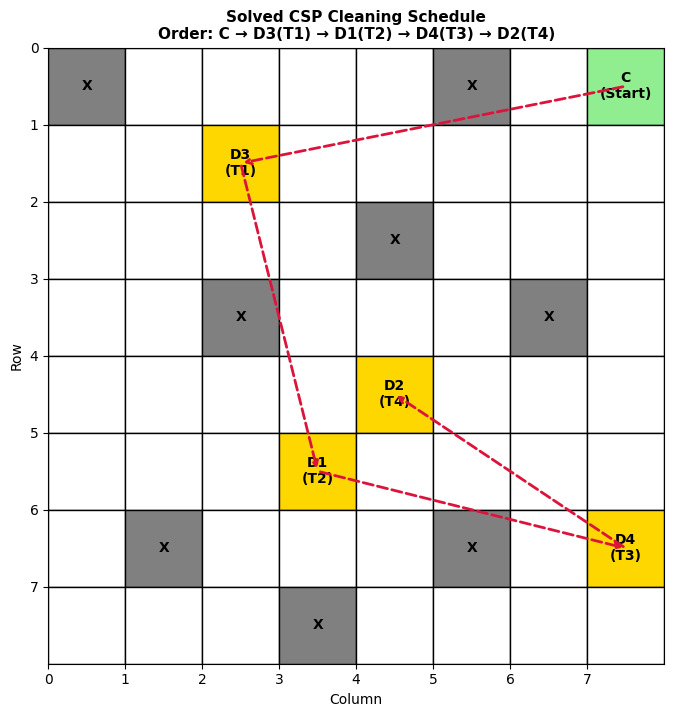

In [16]:
def visualize_csp_schedule(grid, solution):
    if solution is None:
        print("Cannot visualize: No feasible schedule found.")
        return

    rows, cols = grid["rows"], grid["cols"]
    fig, ax = plt.subplots(figsize=(8, 8))
    ax.set_xlim(0, cols)
    ax.set_ylim(rows, 0)
    ax.set_aspect("equal")

    # Draw grid cells with assigned time slots
    for r in range(rows):
        for c in range(cols):
            color, label = "white", ""
            if (r, c) in grid["obstacles"]:
                color, label = "gray", "X"
            elif (r, c) in grid["dirty_locations"]:
                color = "gold"
                idx = grid["dirty_locations"].index((r, c)) + 1
                task = f"D{idx}"
                slot = solution.get(task, "?")
                label = f"{task}\n({slot})"
            elif (r, c) == grid["charging_station"]:
                color, label = "lightgreen", "C\n(Start)"

            ax.add_patch(plt.Rectangle((c, r), 1, 1, facecolor=color, edgecolor="black"))
            if label:
                ax.text(c + 0.5, r + 0.5, label, ha="center", va="center", fontsize=10, fontweight="bold")

    # Draw scheduled order arrows: C -> T1 -> T2 -> T3 -> T4
    ordered_tasks = sorted(solution.items(), key=lambda x: slot_num(x[1]))
    waypoints = [grid["charging_station"]] + [dirty_map[task] for task, _ in ordered_tasks]

    for i in range(len(waypoints) - 1):
        r1, c1 = waypoints[i]
        r2, c2 = waypoints[i + 1]
        ax.annotate(
            "",
            xy=(c2 + 0.5, r2 + 0.5),
            xytext=(c1 + 0.5, r1 + 0.5),
            arrowprops=dict(arrowstyle="->", color="crimson", lw=2, ls="--")
        )

    order_str = " → ".join(["C"] + [f"{t}({s})" for t, s in ordered_tasks])
    ax.set_xticks(range(cols))
    ax.set_yticks(range(rows))
    ax.set_title(f"Solved CSP Cleaning Schedule\nOrder: {order_str}", fontsize=11, fontweight="bold")
    ax.set_xlabel("Column")
    ax.set_ylabel("Row")
    plt.grid(False)
    plt.show()

visualize_csp_schedule(grid, solution)

### 5. Edge Cases & Validation Suite
Tests the CSP solver against all critical edge cases specified in the project requirements:
1. **Unconstrained Variable:** A dirty location (`D4`) does not appear in any precedence or latest-slot constraint, yet must still be assigned a valid exclusive slot.
2. **More Time Slots than Tasks ($m > n$):** 6 available time slots (`T1`–`T6`) for 4 tasks.
3. **Insufficient Time Slots ($m < n$):** Only 3 time slots for 4 tasks (must fail due to slot-exclusivity).
4. **Latest-Slot Bottleneck:** Two tasks forced into `T1` (`D1 <= T1` and `D2 <= T1`), violating slot-exclusivity (must fail).
5. **Cyclic Precedence Deadlock:** `D1 < D2 < D3 < D1` (must fail).

In [17]:
def run_edge_case(title, test_vars, test_slots, prec, latest, expect_success):
    test_domains = {v: list(test_slots) for v in test_vars}
    test_constraints = {
        "time_slots": test_slots,
        "precedence": prec,
        "latest_slot": latest
    }
    res = backtracking_search(test_vars, test_domains, test_constraints)
    passed = (res is not None) == expect_success
    status = "SUCCESS (Schedule Found)" if res is not None else "FAILURE (Infeasible Detected)"

    print(f"[{ 'PASS' if passed else 'FAIL' }] {title}")
    print(f"       Status: {status} -> {res}\n")

print("=" * 65)
print("CSP EDGE CASES VERIFICATION")
print("=" * 65)

# Case 1: D4 is completely unconstrained (not mentioned in Schedule.txt constraints)
run_edge_case(
    "Case 1: Unconstrained Task (D4 has no constraints)",
    variables, ["T1", "T2", "T3", "T4"],
    prec=[("D3", "D1"), ("D1", "D2")],
    latest=[("D1", "T2")],
    expect_success=True
)

# Case 2: More time slots than dirty locations (6 slots for 4 tasks)
run_edge_case(
    "Case 2: Extra Time Slots Available (6 slots, 4 tasks)",
    variables, ["T1", "T2", "T3", "T4", "T5", "T6"],
    prec=[("D3", "D1"), ("D1", "D2"), ("D3", "D4")],
    latest=[("D1", "T2"), ("D4", "T4")],
    expect_success=True
)

# Case 3: Fewer time slots than dirty locations (3 slots for 4 tasks)
run_edge_case(
    "Case 3: Insufficient Time Slots (3 slots, 4 tasks)",
    variables, ["T1", "T2", "T3"],
    prec=[("D3", "D1")],
    latest=[],
    expect_success=False
)

# Case 4: Latest-slot bottleneck (D1 < D2, but D2 must be by T1)
run_edge_case(
    "Case 4: Impossible Latest-Slot Bound (D1 before D2, but D2 by T1)",
    variables, ["T1", "T2", "T3", "T4"],
    prec=[("D1", "D2")],
    latest=[("D2", "T1")],
    expect_success=False
)

# Case 5: Cyclic precedence constraint (D1 < D2 < D3 < D1)
run_edge_case(
    "Case 5: Cyclic Precedence Deadlock (D1 -> D2 -> D3 -> D1)",
    variables, ["T1", "T2", "T3", "T4"],
    prec=[("D1", "D2"), ("D2", "D3"), ("D3", "D1")],
    latest=[],
    expect_success=False
)

CSP EDGE CASES VERIFICATION
[PASS] Case 1: Unconstrained Task (D4 has no constraints)
       Status: SUCCESS (Schedule Found) -> {'D1': 'T2', 'D3': 'T1', 'D2': 'T3', 'D4': 'T4'}

[PASS] Case 2: Extra Time Slots Available (6 slots, 4 tasks)
       Status: SUCCESS (Schedule Found) -> {'D1': 'T2', 'D3': 'T1', 'D4': 'T3', 'D2': 'T4'}

[PASS] Case 3: Insufficient Time Slots (3 slots, 4 tasks)
       Status: FAILURE (Infeasible Detected) -> None

[PASS] Case 4: Impossible Latest-Slot Bound (D1 before D2, but D2 by T1)
       Status: FAILURE (Infeasible Detected) -> None

[PASS] Case 5: Cyclic Precedence Deadlock (D1 -> D2 -> D3 -> D1)
       Status: FAILURE (Infeasible Detected) -> None

